# 04 – Fine-Tuning
**Coursework Topic 6 – News Topic Classification (AG News)**

Train toàn bộ DistilBERT + Classification Head. Cùng kiến trúc, tokenizer, `max_len`, dữ liệu với Frozen Encoder; khác duy nhất là encoder **không** bị đóng băng.

```
Text → Tokenizer → DistilBERT (TRAINABLE) → Mean pooling → Head (TRAINABLE) → 4 lớp
```

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent            # notebook chạy trong thư mục notebooks/
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src import train as ft
from src.data import LABEL_NAMES

## 1. Cấu hình
`QUICK_TEST = True` để chạy thử nhanh: kết quả ghi vào `results/_quick_test/`, **không** đè file chính thức.
Đổi thành `False` để chạy chính thức (Thứ 5). Nên chạy trên GPU (Colab/Kaggle); chạy CPU rất lâu.

In [2]:
QUICK_TEST = True

if QUICK_TEST:
    cfg = dict(train_size=5000, val_size=1000, test_size=1000, epochs=1)
else:
    cfg = dict(train_size=None, val_size=None, test_size=None, epochs=3)  # toàn bộ AG News

print(cfg)

{'train_size': 5000, 'val_size': 1000, 'test_size': 1000, 'epochs': 1}


## 2. Chạy thí nghiệm
Load dữ liệu → tokenize theo batch → fine-tune → chọn epoch tốt nhất theo validation → đánh giá test → lưu metrics, predictions, checkpoint.

In [3]:
out = ft.run_experiment(max_len=64, batch_size=32, lr=2e-5, seed=42, **cfg)

Device: cpu | backbone: distilbert-base-uncased | output: C:\Users\hop98\Documents\Deep_Learning\CourseWork\Course-Work-6\results\_quick_test
QUICK TEST: subsampled data, results go to results/_quick_test/ (not official).
train/val/test = 5000/1000/1000


c:\Users\hop98\anaconda\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hop98\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\hop98\anaconda\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hop98\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

validate:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: train_loss=0.5411 val_acc=0.8810


test:   0%|          | 0/16 [00:00<?, ?it/s]

Test: acc=0.8860 macroF1=0.8872 | train 836.7s | infer 41.4s


## 3. Tham số và kích thước mô hình

In [4]:
row = out["row"]
print(f"Total params     : {row['total_params']:,}")
print(f"Trainable params : {row['trainable_params']:,}")
print(f"Model size       : {row['model_size_mb']:.1f} MB (checkpoint file: {row['checkpoint_size_mb']:.1f} MB)")
print(f"Best epoch       : {row['best_epoch']} (val acc {row['best_val_accuracy']:.4f})")

Total params     : 66,365,956
Trainable params : 66,365,956
Model size       : 253.2 MB (checkpoint file: 253.2 MB)
Best epoch       : 1 (val acc 0.8810)


## 4. Kết quả trên tập test

In [5]:
metrics = pd.read_csv(out["metrics_path"])
metrics.T

,0
model,fine_tuning
backbone,distilbert-base-uncased
accuracy,0.886
precision_macro,0.887285
recall_macro,0.887275
f1_macro,0.887176
train_time_s,836.681028
inference_time_s,41.356749
inference_ms_per_sample,41.356749
trainable_params,66365956


In [6]:
print(classification_report(out["y_true"], out["y_pred"], target_names=LABEL_NAMES, digits=4))

              precision    recall  f1-score   support

       World     0.9127    0.8856    0.8989       236
      Sports     0.9595    0.9793    0.9693       242
    Business     0.8120    0.8286    0.8202       245
    Sci/Tech     0.8650    0.8556    0.8603       277

    accuracy                         0.8860      1000
   macro avg     0.8873    0.8873    0.8872      1000
weighted avg     0.8861    0.8860    0.8860      1000



## 5. Learning curve

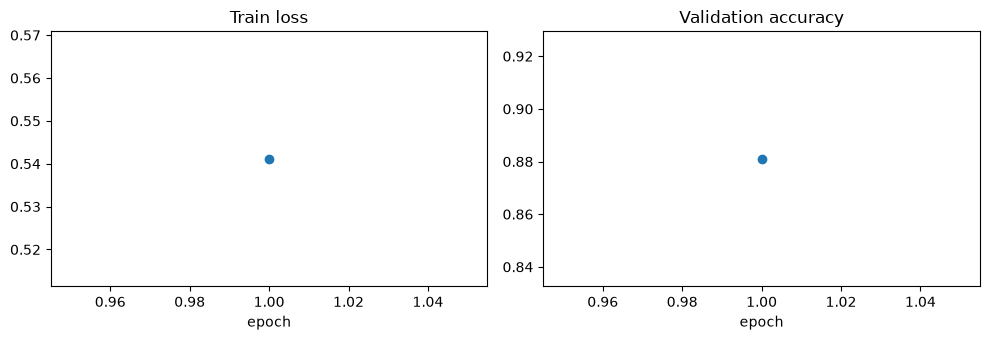

In [7]:
hist = pd.DataFrame(out["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_accuracy"], marker="o"); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Confusion matrix (xem nhanh)
Bản chính thức lưu vào `results/figures/` do `src/evaluate.py` (Trúc Chi) tạo.

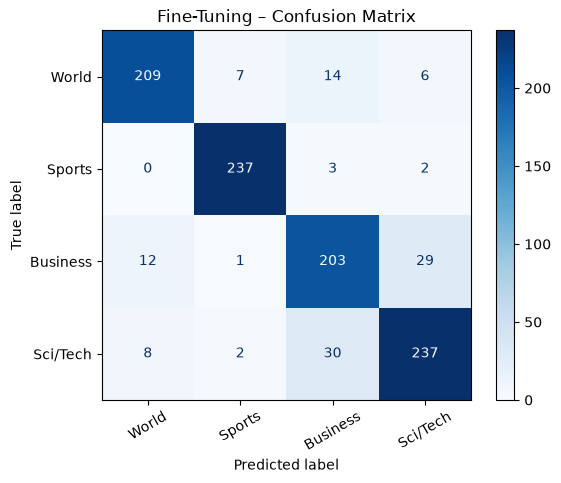

In [8]:
cm = confusion_matrix(out["y_true"], out["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(cmap="Blues", xticks_rotation=30)
plt.title("Fine-Tuning – Confusion Matrix"); plt.show()

## 7. Một vài mẫu dự đoán sai (tự tin cao nhất)

In [9]:
preds = pd.read_csv(out["predictions_path"])
wrong = preds[~preds["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)}/{len(preds)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 114/1000 mẫu


,text,true_name,pred_name,confidence
81,"At Last, Success on the Road for Lions The Det...",World,Sports,0.987649
897,"Cowboys Defeat Redskins 21-18 LANDOVER, Md. - ...",World,Sports,0.986346
9,Chavez rejects CD as opposition Venezuela 's P...,Business,World,0.985317
621,Indonesian diplomats asked to help improve RI ...,Business,World,0.983767
652,Stocks Climb on Drop in Consumer Prices NEW YO...,World,Business,0.978119
312,World briefs LONDON - A man wielding a machete...,Business,World,0.977720
556,Collingwood anchors England (AFP) AFP - Paul C...,World,Sports,0.973084
105,Thailand Shows No Easy War Against Wildlife Cr...,Sci/Tech,World,0.971164
493,Microsoft Launches New Media Center PC Microso...,Business,Sci/Tech,0.970229
816,Stocks Drop After Greenspan Testimony NEW YORK...,World,Business,0.968897


## 8. Thử dự đoán một câu

In [10]:
samples = ["Manchester United won the match 3-1.",
           "Apple unveils a new chip for its laptops.",
           "Stocks fell as oil prices surged on Tuesday."]
names, confs = ft.predict_texts(out["model"], out["tokenizer"], samples, max_len=64)
for s, n, c in zip(samples, names, confs):
    print(f"{n:9s} ({c:.2f})  {s}")

Sports    (0.97)  Manchester United won the match 3-1.
Sci/Tech  (0.96)  Apple unveils a new chip for its laptops.
Business  (0.97)  Stocks fell as oil prices surged on Tuesday.
